In [47]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import FormatStrFormatter
import rioxarray as rxr
from sklearn import cluster
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score
from scipy.stats import mode
from scipy.ndimage import generic_filter
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import gc
import os

In [48]:
# Create figures directory if it doesn't exist
os.makedirs('./Figures', exist_ok=True)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


LOADING DATA
Original data shape: (224, 1182, 1223)
Original data range: [-32768, 7333]


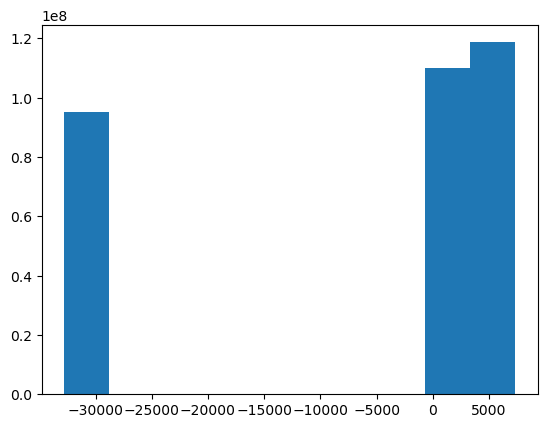

In [49]:
# Load the EnMAP data
print("="*60)
print("LOADING DATA")
print("="*60)
data_enmap = rxr.open_rasterio('Datasets/ENMAP01-____L2A-DT0000160657_20251016T011429Z_002_V010502_20251017T031330Z-SPECTRAL_IMAGE.TIF').squeeze()
print(f"Original data shape: {data_enmap.shape}")
print(f"Original data range: [{data_enmap.min().values}, {data_enmap.max().values}]")
data_enmap.plot()
plt.title('')
plt.show()

In [50]:
# Print CRS information
print("CRS:", data_enmap.rio.crs)

CRS: EPSG:32754


In [51]:
# Get bounds (xmin, ymin, xmax, ymax)
xmin, ymin, xmax, ymax = data_enmap.rio.bounds()

print(f"Xmin: {xmin}")
print(f"Xmax: {xmax}")
print(f"Ymin: {ymin}")
print(f"Ymax: {ymax}")

Xmin: 567075.0
Xmax: 603765.0
Ymin: 6712245.0
Ymax: 6747705.0


Scaled data range: [0.0, 0.733299970626831]


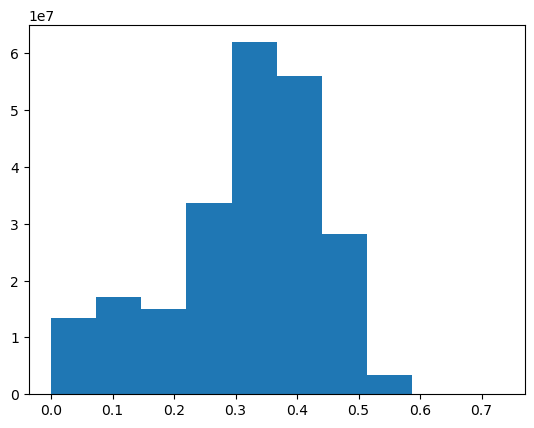

Spatial extent: [array(567090.), array(603750.), array(6712260.), array(6747690.)]


In [52]:
# Replace fill values with NaN
data_enmap = data_enmap.where(data_enmap >= 0)
# Scale to reflectance (0-1 range)
data_enmap = data_enmap / 10000.0
print(f"Scaled data range: [{data_enmap.min().values}, {data_enmap.max().values}]")
data_enmap.plot()
plt.title('')
plt.show()

# Get the spatial extent
extent = [data_enmap.x.min().values, data_enmap.x.max().values,
          data_enmap.y.min().values, data_enmap.y.max().values]
print(f"Spatial extent: {extent}")

In [53]:
# Prepare data with band-wise validation
# Get the shape
if len(data_enmap.shape) == 3:
    bands, rows, cols = data_enmap.shape
else:
    raise ValueError(f"Expected 3D data (bands, rows, cols), got shape {data_enmap.shape}")

print(f"Data shape: {bands} bands, {rows} rows, {cols} columns")
print(f"Total pixels: {rows * cols:,}")

# Reshape to 2D: (n_pixels, n_bands)
print("\nReshaping data...")
data_reshaped = data_enmap.values.reshape(bands, -1).T
print(f"Reshaped to: {data_reshaped.shape} (pixels × bands)")

Data shape: 224 bands, 1182 rows, 1223 columns
Total pixels: 1,445,586

Reshaping data...
Reshaped to: (1445586, 224) (pixels × bands)


In [54]:
# Step 1: Identify bands with valid data
print("\n" + "="*60)
print("STEP 1: IDENTIFYING VALID BANDS")
print("="*60)
print("Checking which bands have valid data...")
bands_with_data = []
bands_without_data = []

for band_idx in range(bands):
    band_mean = np.nanmean(data_reshaped[:, band_idx])
    if not np.isnan(band_mean):
        bands_with_data.append(band_idx)
    else:
        bands_without_data.append(band_idx)

print(f"\nBands with valid data: {len(bands_with_data)} out of {bands}")
print(f"Bands with NO valid data: {len(bands_without_data)}")

if len(bands_without_data) > 0:
    if len(bands_without_data) <= 20:
        print(f"Problematic bands removed: {bands_without_data}")
    else:
        print(f"First 20 problematic bands: {bands_without_data[:20]}")
        print(f"... and {len(bands_without_data) - 20} more")

# Step 2: Keep only valid bands
print("\n" + "="*60)
print("STEP 2: KEEPING ONLY VALID BANDS")
print("="*60)
data_reshaped_valid_bands = data_reshaped[:, bands_with_data]
print(f"New data shape: {data_reshaped_valid_bands.shape}")
print(f"Removed {len(bands_without_data)} invalid bands")

# Step 3: Fill remaining NaN values with band means
print("\n" + "="*60)
print("STEP 3: FILLING NaN VALUES WITH BAND MEANS")
print("="*60)
data_reshaped_filled = data_reshaped_valid_bands.copy()
print("Filling NaN values with band means...")
total_nans_filled = 0

for i, band_idx in enumerate(bands_with_data):
    band_data = data_reshaped_filled[:, i]
    nan_count = np.isnan(band_data).sum()
    
    if nan_count > 0:
        band_mean = np.nanmean(band_data)
        data_reshaped_filled[:, i] = np.where(np.isnan(band_data), band_mean, band_data)
        total_nans_filled += nan_count
        
        if i % 50 == 0 or i < 5:
            print(f"  Band {i} (original band {band_idx}): Filled {nan_count} NaNs with mean {band_mean:.4f}")

print(f"\nTotal NaN values filled: {total_nans_filled:,}")

# Step 4: Remove completely invalid pixels
print("\n" + "="*60)
print("STEP 4: REMOVING COMPLETELY INVALID PIXELS")
print("="*60)
nan_count_per_pixel = np.isnan(data_reshaped).sum(axis=1)
completely_invalid = nan_count_per_pixel == bands
data_valid = data_reshaped_filled[~completely_invalid]
valid_mask_full = ~completely_invalid

print(f"\nFinal statistics:")
print(f"  Original bands: {bands}")
print(f"  Valid bands used: {len(bands_with_data)}")
print(f"  Total pixels: {data_reshaped.shape[0]:,}")
print(f"  Completely invalid pixels removed: {completely_invalid.sum():,}")
print(f"  Valid pixels for autoencoder: {data_valid.shape[0]:,}")
print(f"  Final shape: {data_valid.shape}")
print(f"  NaN values remaining: {np.isnan(data_valid).sum()}")

if data_valid.shape[0] > 0 and np.isnan(data_valid).sum() == 0:
    print("\n✓ Data is ready for Stacked Autoencoder!")
else:
    raise ValueError("✗ Error: Data still has issues.")

# Convert to float32 and make contiguous
data_reshaped = data_valid.astype(np.float32)
if not data_reshaped.flags['C_CONTIGUOUS']:
    data_reshaped = np.ascontiguousarray(data_reshaped)

print(f"\nData ready for training:")
print(f"  Shape: {data_reshaped.shape}")
print(f"  dtype: {data_reshaped.dtype}")
print(f"  Size: {data_reshaped.nbytes / 1024**2:.2f} MB")


STEP 1: IDENTIFYING VALID BANDS
Checking which bands have valid data...


/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_8656/4266488971.py:10: RuntimeWarning: Mean of empty slice
  band_mean = np.nanmean(data_reshaped[:, band_idx])



Bands with valid data: 219 out of 224
Bands with NO valid data: 5
Problematic bands removed: [130, 131, 132, 133, 134]

STEP 2: KEEPING ONLY VALID BANDS
New data shape: (1445586, 219)
Removed 5 invalid bands

STEP 3: FILLING NaN VALUES WITH BAND MEANS
Filling NaN values with band means...
  Band 0 (original band 0): Filled 403469 NaNs with mean 0.0443
  Band 1 (original band 1): Filled 403702 NaNs with mean 0.0447
  Band 2 (original band 2): Filled 403041 NaNs with mean 0.0489
  Band 3 (original band 3): Filled 402919 NaNs with mean 0.0514
  Band 4 (original band 4): Filled 402710 NaNs with mean 0.0556
  Band 50 (original band 50): Filled 401494 NaNs with mean 0.2601
  Band 100 (original band 100): Filled 401487 NaNs with mean 0.3286
  Band 150 (original band 155): Filled 401489 NaNs with mean 0.4465
  Band 200 (original band 205): Filled 401483 NaNs with mean 0.3460

Total NaN values filled: 87,943,394

STEP 4: REMOVING COMPLETELY INVALID PIXELS

Final statistics:
  Original bands: 2

In [55]:
# Define Stacked Autoencoder Models
class Autoencoder1(nn.Module):
    """First autoencoder: input_dim -> 6 -> 4 -> 2 -> 4 -> 6 -> input_dim"""
    def __init__(self, input_dim, l1_lambda=1e-4):
        super(Autoencoder1, self).__init__()
        self.l1_lambda = l1_lambda
        
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 6),
            nn.SELU(),
            nn.Linear(6, 4),
            nn.SELU(),
            nn.Linear(4, 2),
            nn.SELU()
        )
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(2, 4),
            nn.SELU(),
            nn.Linear(4, 6),
            nn.SELU(),
            nn.Linear(6, input_dim),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded
    
    def l1_regularization(self):
        l1_loss = 0
        for param in self.parameters():
            l1_loss += torch.sum(torch.abs(param))
        return self.l1_lambda * l1_loss


class Autoencoder2(nn.Module):
    """Second autoencoder: input_dim -> 10 -> 5 -> 2 -> 5 -> 10 -> input_dim"""
    def __init__(self, input_dim, l1_lambda=1e-4):
        super(Autoencoder2, self).__init__()
        self.l1_lambda = l1_lambda
        
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 10),
            nn.SELU(),
            nn.Linear(10, 5),
            nn.SELU(),
            nn.Linear(5, 2),
            nn.SELU()
        )
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(2, 5),
            nn.SELU(),
            nn.Linear(5, 10),
            nn.SELU(),
            nn.Linear(10, input_dim),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded
    
    def encode_to_layer2(self, x):
        """Returns output of second encoder layer (5 dimensions)"""
        x = self.encoder[0](x)  # Linear input_dim -> 10
        x = self.encoder[1](x)  # SELU
        x = self.encoder[2](x)  # Linear 10 -> 5
        x = self.encoder[3](x)  # SELU
        return x
    
    def l1_regularization(self):
        l1_loss = 0
        for param in self.parameters():
            l1_loss += torch.sum(torch.abs(param))
        return self.l1_lambda * l1_loss


class Autoencoder3(nn.Module):
    """Third autoencoder: input_dim -> 15 -> 10 -> 5 -> 2 -> 5 -> 10 -> 15 -> input_dim"""
    def __init__(self, input_dim, l1_lambda=1e-4):
        super(Autoencoder3, self).__init__()
        self.l1_lambda = l1_lambda
        
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 15),
            nn.SELU(),
            nn.Linear(15, 10),
            nn.SELU(),
            nn.Linear(10, 5),
            nn.SELU(),
            nn.Linear(5, 2),
            nn.SELU()
        )
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(2, 5),
            nn.SELU(),
            nn.Linear(5, 10),
            nn.SELU(),
            nn.Linear(10, 15),
            nn.SELU(),
            nn.Linear(15, input_dim),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded
    
    def encode(self, x):
        return self.encoder(x)
    
    def l1_regularization(self):
        l1_loss = 0
        for param in self.parameters():
            l1_loss += torch.sum(torch.abs(param))
        return self.l1_lambda * l1_loss

In [56]:
def train_autoencoder(model, data, epochs, batch_size, learning_rate, model_name="Autoencoder"):
    """Generic training function for autoencoders"""
    print(f"\n{'='*60}")
    print(f"TRAINING {model_name}")
    print(f"{'='*60}")
    print(f"Input shape: {data.shape}")
    print(f"Epochs: {epochs}")
    print(f"Batch size: {batch_size}")
    
    # Convert to PyTorch tensor
    data_tensor = torch.FloatTensor(data).to(device)
    
    # Create DataLoader
    dataset = TensorDataset(data_tensor, data_tensor)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    # Setup training
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    
    history = {'loss': [], 'accuracy': []}
    
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        epoch_correct = 0
        epoch_total = 0
        
        for batch_x, batch_y in dataloader:
            # Forward pass
            outputs = model(batch_x)
            
            # Calculate loss (MSE + L1 regularization)
            mse_loss = criterion(outputs, batch_y)
            l1_loss = model.l1_regularization()
            loss = mse_loss + l1_loss
            
            # Backward pass and optimization
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            # Track metrics
            epoch_loss += loss.item()
            
            # Calculate "accuracy"
            with torch.no_grad():
                diff = torch.abs(outputs - batch_y)
                correct = (diff < 0.1).float().mean()
                epoch_correct += correct.item()
                epoch_total += 1
        
        avg_loss = epoch_loss / len(dataloader)
        avg_accuracy = epoch_correct / epoch_total
        
        history['loss'].append(avg_loss)
        history['accuracy'].append(avg_accuracy)
        
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.6f}, Accuracy: {avg_accuracy:.4f}")
    
    print(f"✓ {model_name} training complete!")
    
    return history

In [57]:
# Hyperparameters
learning_rate = 1e-4

# ============================================================================
# STACK 1: Train first autoencoder
# ============================================================================
print("\n" + "="*60)
print("STACK 1: FIRST AUTOENCODER")
print("="*60)

input_dim_1 = data_reshaped.shape[1]
autoencoder_1 = Autoencoder1(input_dim_1, l1_lambda=learning_rate).to(device)

stack_1_history = train_autoencoder(
    model=autoencoder_1,
    data=data_reshaped,
    epochs=10,
    batch_size=64,
    learning_rate=learning_rate,
    model_name="Autoencoder 1"
)

# Get output from autoencoder 1 and concatenate with original data
print("\nGenerating input for Autoencoder 2...")
autoencoder_1.eval()
with torch.no_grad():
    data_tensor = torch.FloatTensor(data_reshaped).to(device)
    autoencoder_2_input_reconstructed = autoencoder_1(data_tensor).cpu().numpy()

autoencoder_2_input = np.concatenate((autoencoder_2_input_reconstructed, data_reshaped), axis=1)
print(f"Autoencoder 2 input shape: {autoencoder_2_input.shape}")

# Clean up
del data_tensor
if device.type == 'cuda':
    torch.cuda.empty_cache()
gc.collect()

# ============================================================================
# STACK 2: Train second autoencoder
# ============================================================================
print("\n" + "="*60)
print("STACK 2: SECOND AUTOENCODER")
print("="*60)

input_dim_2 = autoencoder_2_input.shape[1]
autoencoder_2 = Autoencoder2(input_dim_2, l1_lambda=learning_rate).to(device)

stack_2_history = train_autoencoder(
    model=autoencoder_2,
    data=autoencoder_2_input,
    epochs=5,
    batch_size=32,
    learning_rate=learning_rate,
    model_name="Autoencoder 2"
)

# Get encoder output (layer 2) and concatenate with autoencoder 2 input
print("\nGenerating input for Autoencoder 3...")
autoencoder_2.eval()
with torch.no_grad():
    data_tensor = torch.FloatTensor(autoencoder_2_input).to(device)
    autoencoder_3_input_encoded = autoencoder_2.encode_to_layer2(data_tensor).cpu().numpy()

autoencoder_3_input = np.concatenate((autoencoder_3_input_encoded, autoencoder_2_input), axis=1)
print(f"Autoencoder 3 input shape: {autoencoder_3_input.shape}")

# Clean up
del data_tensor
if device.type == 'cuda':
    torch.cuda.empty_cache()
gc.collect()

# ============================================================================
# STACK 3: Train third autoencoder
# ============================================================================
print("\n" + "="*60)
print("STACK 3: THIRD AUTOENCODER")
print("="*60)

input_dim_3 = autoencoder_3_input.shape[1]
autoencoder_3 = Autoencoder3(input_dim_3, l1_lambda=learning_rate).to(device)

stack_3_history = train_autoencoder(
    model=autoencoder_3,
    data=autoencoder_3_input,
    epochs=5,
    batch_size=16,
    learning_rate=learning_rate,
    model_name="Autoencoder 3"
)



STACK 1: FIRST AUTOENCODER

TRAINING Autoencoder 1
Input shape: (1044103, 219)
Epochs: 10
Batch size: 64
Epoch [1/10], Loss: 0.014708, Accuracy: 0.8935
Epoch [2/10], Loss: 0.004654, Accuracy: 0.9650
Epoch [3/10], Loss: 0.003436, Accuracy: 0.9871
Epoch [4/10], Loss: 0.003087, Accuracy: 0.9887
Epoch [5/10], Loss: 0.003028, Accuracy: 0.9890
Epoch [6/10], Loss: 0.002996, Accuracy: 0.9890
Epoch [7/10], Loss: 0.002991, Accuracy: 0.9890
Epoch [8/10], Loss: 0.002991, Accuracy: 0.9890
Epoch [9/10], Loss: 0.002990, Accuracy: 0.9890
Epoch [10/10], Loss: 0.002990, Accuracy: 0.9890
✓ Autoencoder 1 training complete!

Generating input for Autoencoder 2...
Autoencoder 2 input shape: (1044103, 438)

STACK 2: SECOND AUTOENCODER

TRAINING Autoencoder 2
Input shape: (1044103, 438)
Epochs: 5
Batch size: 32
Epoch [1/5], Loss: 0.010819, Accuracy: 0.9455
Epoch [2/5], Loss: 0.003097, Accuracy: 0.9917
Epoch [3/5], Loss: 0.002741, Accuracy: 0.9932
Epoch [4/5], Loss: 0.002697, Accuracy: 0.9936
Epoch [5/5], Loss


Generating final encoded representation...
✓ Final encoded shape: (1044103, 2)
  Encoded data range: [-1.539, 0.184]

Plotting training histories...


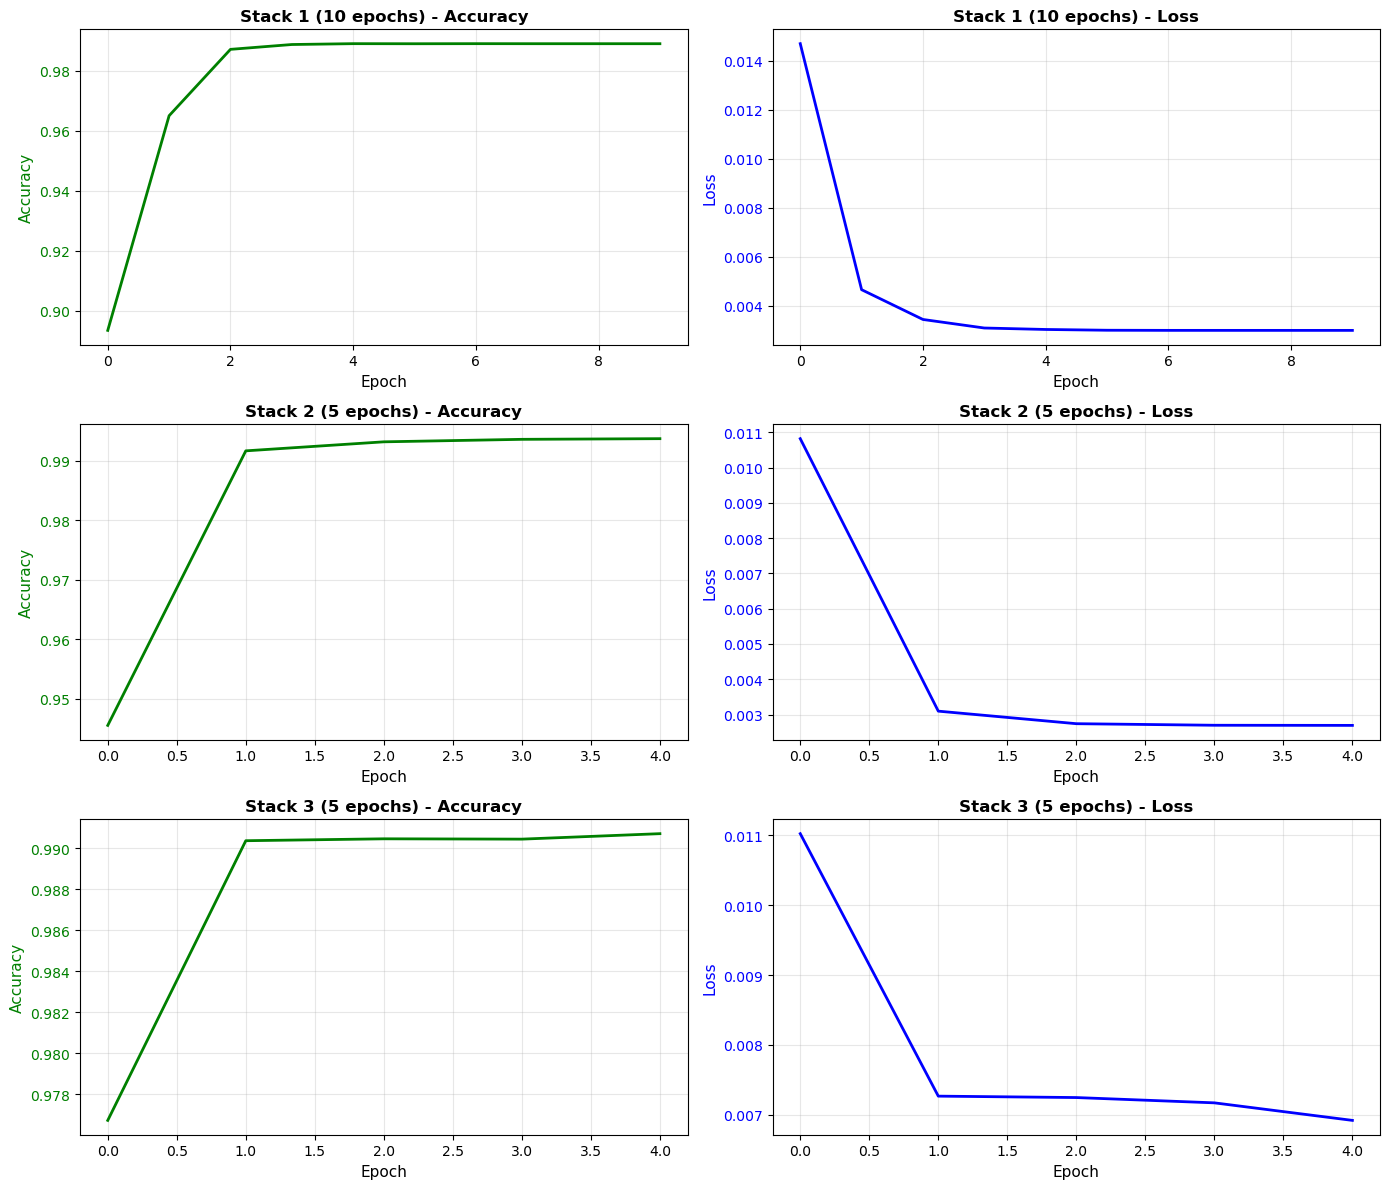

✓ Training history saved to './Figures/sae_training_history.png'


In [58]:
# Get final encoded representation
print("\nGenerating final encoded representation...")
autoencoder_3.eval()
with torch.no_grad():
    data_tensor = torch.FloatTensor(autoencoder_3_input).to(device)
    data_sae = autoencoder_3.encode(data_tensor).cpu().numpy()

print(f"✓ Final encoded shape: {data_sae.shape}")
print(f"  Encoded data range: [{data_sae.min():.3f}, {data_sae.max():.3f}]")

# Clean up
del data_tensor
if device.type == 'cuda':
    torch.cuda.empty_cache()
gc.collect()

# Plot training histories
print("\nPlotting training histories...")
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

histories = [
    (stack_1_history, "Stack 1 (10 epochs)"),
    (stack_2_history, "Stack 2 (5 epochs)"),
    (stack_3_history, "Stack 3 (5 epochs)")
]

for idx, (history, title) in enumerate(histories):
    # Accuracy
    axes[idx, 0].plot(history['accuracy'], 'g-', linewidth=2)
    axes[idx, 0].set_title(f'{title} - Accuracy', fontsize=12, fontweight='bold')
    axes[idx, 0].set_ylabel('Accuracy', color='g', fontsize=11)
    axes[idx, 0].set_xlabel('Epoch', fontsize=11)
    axes[idx, 0].grid(True, alpha=0.3)
    axes[idx, 0].tick_params(axis='y', labelcolor='g')
    
    # Loss
    axes[idx, 1].plot(history['loss'], 'b-', linewidth=2)
    axes[idx, 1].set_title(f'{title} - Loss', fontsize=12, fontweight='bold')
    axes[idx, 1].set_ylabel('Loss', color='b', fontsize=11)
    axes[idx, 1].set_xlabel('Epoch', fontsize=11)
    axes[idx, 1].grid(True, alpha=0.3)
    axes[idx, 1].tick_params(axis='y', labelcolor='b')

plt.tight_layout()
plt.savefig('./Figures/sae_training_history.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Training history saved to './Figures/sae_training_history.png'")


ELBOW METHOD - FINDING OPTIMAL K
Testing different numbers of clusters...
  k=2: inertia=22687.88
  k=3: inertia=11731.96
  k=4: inertia=7888.98
  k=5: inertia=4716.49
  k=6: inertia=3476.19
  k=7: inertia=2590.80
  k=8: inertia=2008.50
  k=9: inertia=1661.45
  k=10: inertia=1332.55
  k=11: inertia=1115.30
  k=12: inertia=953.09
  k=13: inertia=818.48
  k=14: inertia=723.30
  k=15: inertia=643.76
  k=16: inertia=550.60
  k=17: inertia=491.59
  k=18: inertia=442.80
  k=19: inertia=410.95
  k=20: inertia=367.91


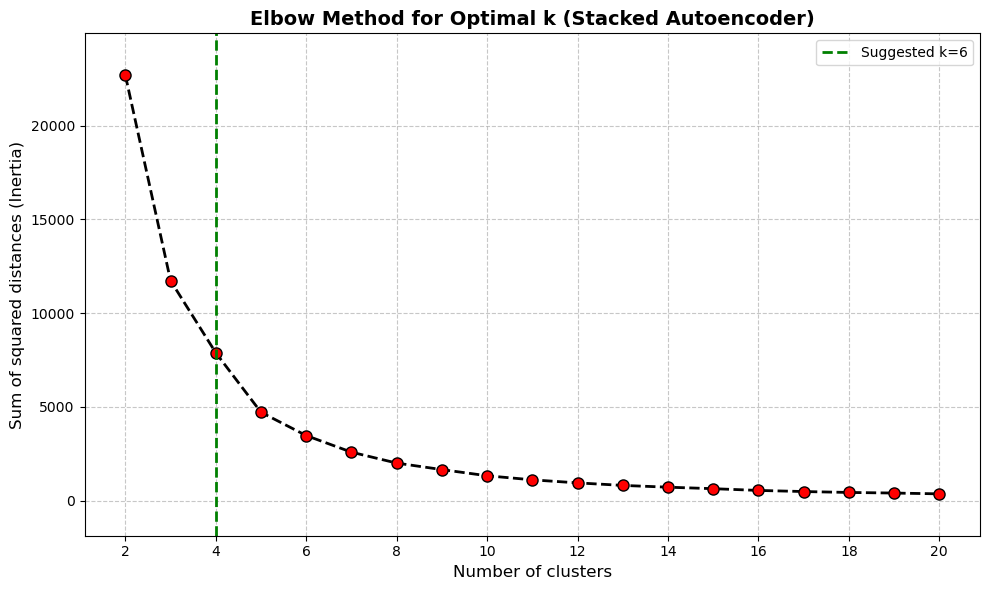


✓ Elbow plot saved to './Figures/sae_kmeans_enmap_elbow.png'


In [59]:
print("\n" + "="*60)
print("ELBOW METHOD - FINDING OPTIMAL K")
print("="*60)

sum_squared_distance = []
range_n_clusters = range(2, 21)

print("Testing different numbers of clusters...")
for k in range_n_clusters:
    clusterer = cluster.KMeans(n_clusters=k, random_state=1)
    clusterer.fit(data_sae)
    sum_squared_distance.append(clusterer.inertia_)
    print(f"  k={k}: inertia={clusterer.inertia_:.2f}")

range_ssd = max(sum_squared_distance) - min(sum_squared_distance)

# Plot elbow graph
plt.figure(figsize=(10, 6))
plt.plot(range_n_clusters, sum_squared_distance, 'ko--', mfc='r', linewidth=2, markersize=8)
plt.vlines(x=4, ymin=min(sum_squared_distance)-(0.1*range_ssd),
           ymax=max(sum_squared_distance)+(0.1*range_ssd), color='g', linestyles='dashed', linewidth=2, label='Suggested k=4')
plt.xticks(range(2, 21, 2))
plt.ylim(min(sum_squared_distance)-(0.1*range_ssd), max(sum_squared_distance)+(0.1*range_ssd))
plt.xlabel('Number of clusters', fontsize=12)
plt.ylabel('Sum of squared distances (Inertia)', fontsize=12)
plt.title('Elbow Method for Optimal k (Stacked Autoencoder)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('./Figures/sae_kmeans_enmap_elbow.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Elbow plot saved to './Figures/sae_kmeans_enmap_elbow.png'")

In [60]:
print("\n" + "="*60)
print("K-MEANS CLUSTERING")
print("="*60)

n_clusters = 4
print(f"Clustering with k={n_clusters}...")

# Create and train the classifier
clusterer = cluster.KMeans(n_clusters=n_clusters, random_state=1)
pred = clusterer.fit_predict(data_sae)

# Get cluster labels
labels = clusterer.labels_

print(f"✓ Clustering complete!")
print(f"  Cluster labels shape: {labels.shape}")
print(f"  Unique clusters: {np.unique(labels)}")

# Calculate clustering metrics
ch_score = calinski_harabasz_score(data_sae, labels)
db_score = davies_bouldin_score(data_sae, labels)

print(f"\nClustering Quality Metrics:")
print(f"  Calinski-Harabasz score: {round(ch_score, 4)} (higher is better)")
print(f"  Davies-Bouldin score: {round(db_score, 4)} (lower is better)")

# Count pixels per cluster
unique = np.unique(labels)
counts = np.bincount(labels)
print(f"\nPixels per cluster:")
for cluster_id, count in enumerate(counts):
    print(f"  Cluster {cluster_id}: {count:,} pixels ({100*count/len(labels):.1f}%)")



K-MEANS CLUSTERING
Clustering with k=4...
✓ Clustering complete!
  Cluster labels shape: (1044103,)
  Unique clusters: [0 1 2 3]

Clustering Quality Metrics:
  Calinski-Harabasz score: 3473481.1527 (higher is better)
  Davies-Bouldin score: 0.5245 (lower is better)

Pixels per cluster:
  Cluster 0: 148,978 pixels (14.3%)
  Cluster 1: 403,979 pixels (38.7%)
  Cluster 2: 225,959 pixels (21.6%)
  Cluster 3: 265,187 pixels (25.4%)


In [61]:
print("\n" + "="*60)
print("RESHAPING LABELS TO SPATIAL DIMENSIONS")
print("="*60)

# Create a full array with NaN for invalid pixels
labels_full = np.full(valid_mask_full.shape, np.nan)
# Fill in the valid pixels with cluster labels
labels_full[valid_mask_full] = labels

# Reshape to original spatial dimensions
labels_spatial = labels_full.reshape(rows, cols)
print(f"Spatial labels shape: {labels_spatial.shape}")
print(f"  Valid pixels: {(~np.isnan(labels_spatial)).sum():,}")
print(f"  Invalid pixels: {np.isnan(labels_spatial).sum():,}")

# Define the filter function for majority filtering
def filter_function(values):
    """Return the most common value in the neighborhood, ignoring NaN"""
    valid_values = values[~np.isnan(values)]
    if len(valid_values) == 0:
        return np.nan
    mode_result = mode(valid_values, keepdims=True)
    return mode_result.mode[0]

# Apply majority filter to smooth the results
print("\nApplying majority filter (7x7 window)...")
labels_major = generic_filter(labels_spatial, function=filter_function, size=7)
print(f"✓ Filtering complete!")


RESHAPING LABELS TO SPATIAL DIMENSIONS
Spatial labels shape: (1182, 1223)
  Valid pixels: 1,044,103
  Invalid pixels: 401,483

Applying majority filter (7x7 window)...
✓ Filtering complete!



PLOTTING CLASSIFICATION MAP


/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_8656/3887177674.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  im = ax.imshow(data, extent=extent, cmap=plt.cm.get_cmap('tab10', n_clusters),


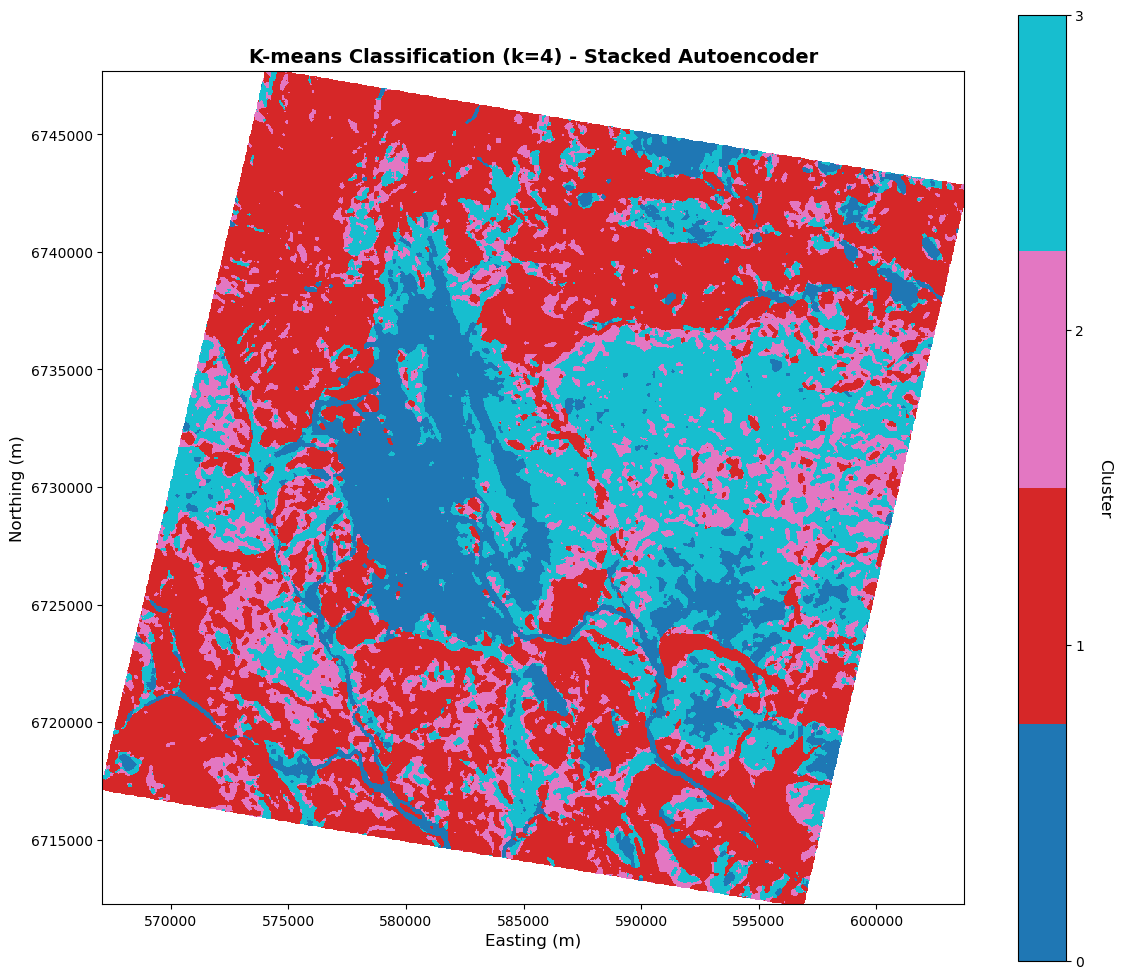


✓ Classification map saved to './Figures/sae_kmeans_enmap_classification.png'

Creating comparison plot...


/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_8656/3887177674.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap=plt.cm.get_cmap('tab10', n_clusters),
/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_8656/3887177674.py:52: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap=plt.cm.get_cmap('tab10', n_clusters),


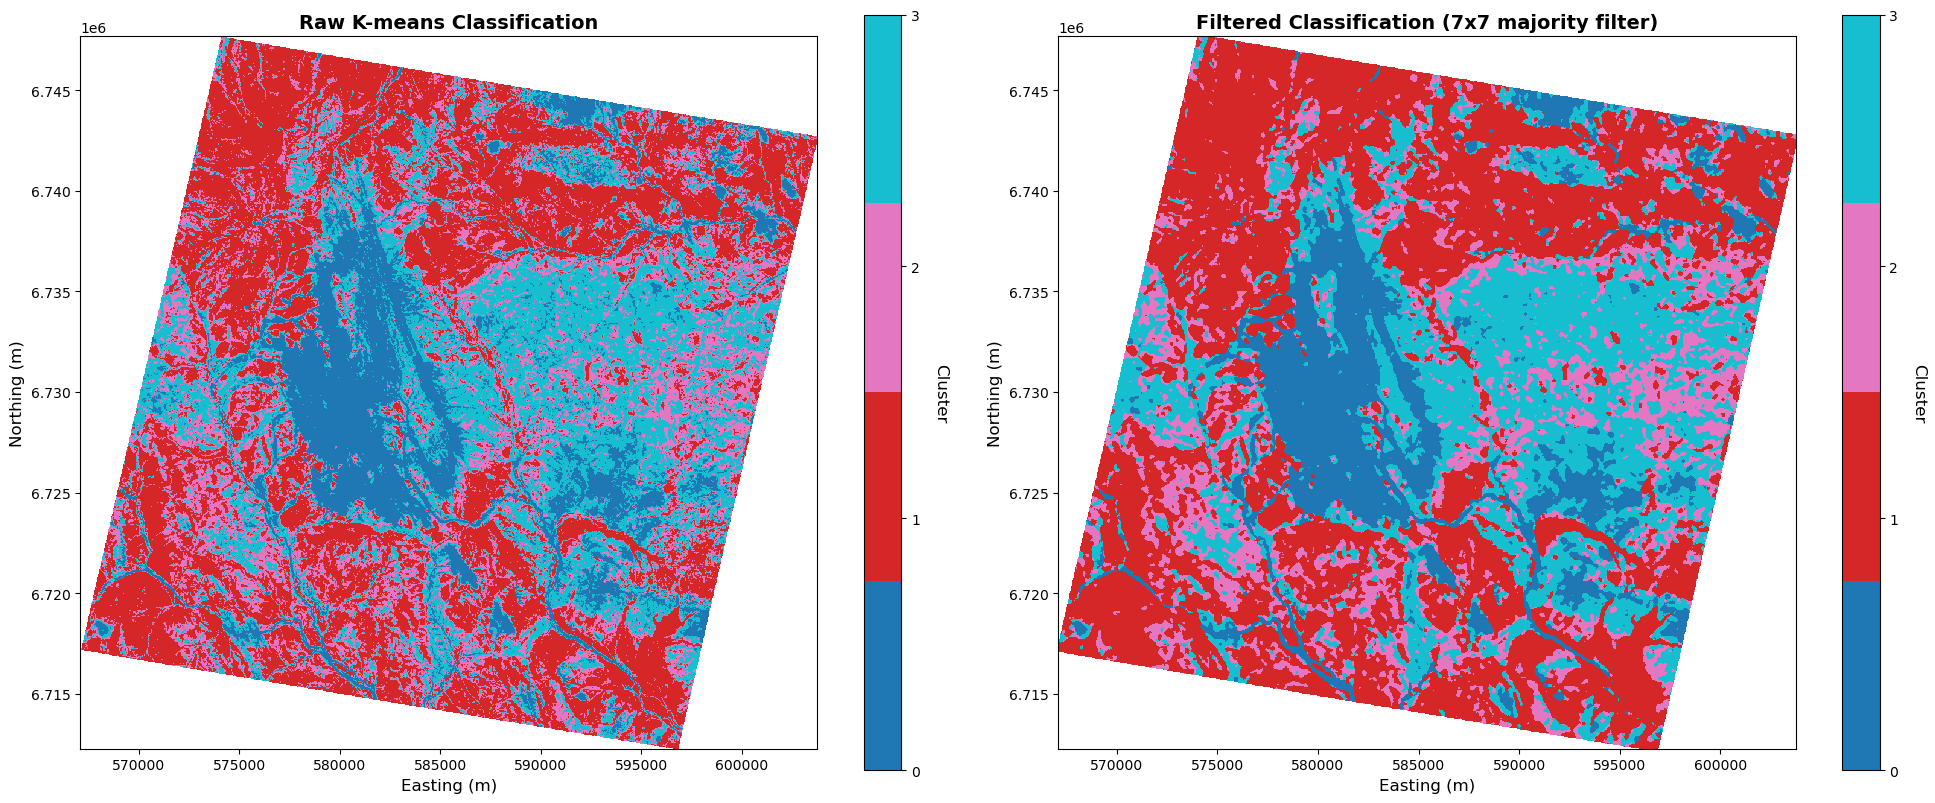

✓ Comparison plot saved to './Figures/sae_kmeans_enmap_comparison.png'


In [62]:
def plot_map(data, extent, n_clusters, title='K-means Classification'):
    """Plot the classification map"""
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Plot the data
    im = ax.imshow(data, extent=extent, cmap=plt.cm.get_cmap('tab10', n_clusters), 
                   interpolation='nearest', vmin=0, vmax=n_clusters-1)
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax, ticks=range(n_clusters))
    cbar.set_label('Cluster', rotation=270, labelpad=20, fontsize=12)
    
    # Labels and formatting
    ax.set_xlabel('Easting (m)', fontsize=12)
    ax.set_ylabel('Northing (m)', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    
    # Format axis ticks
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    
    plt.tight_layout()
    return fig, ax

print("\n" + "="*60)
print("PLOTTING CLASSIFICATION MAP")
print("="*60)

fig, ax = plot_map(labels_major, extent, n_clusters, 
                   title=f'K-means Classification (k={n_clusters}) - Stacked Autoencoder')
plt.savefig('./Figures/sae_kmeans_enmap_classification.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Classification map saved to './Figures/sae_kmeans_enmap_classification.png'")

# Plot both raw and filtered classifications side by side
print("\nCreating comparison plot...")
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Raw classification
im1 = axes[0].imshow(labels_spatial, extent=extent, 
                     cmap=plt.cm.get_cmap('tab10', n_clusters), 
                     interpolation='nearest', vmin=0, vmax=n_clusters-1)
axes[0].set_title('Raw K-means Classification', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Easting (m)', fontsize=12)
axes[0].set_ylabel('Northing (m)', fontsize=12)
cbar1 = plt.colorbar(im1, ax=axes[0], ticks=range(n_clusters))
cbar1.set_label('Cluster', rotation=270, labelpad=20, fontsize=12)

# Filtered classification
im2 = axes[1].imshow(labels_major, extent=extent, 
                     cmap=plt.cm.get_cmap('tab10', n_clusters), 
                     interpolation='nearest', vmin=0, vmax=n_clusters-1)
axes[1].set_title('Filtered Classification (7x7 majority filter)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Easting (m)', fontsize=12)
axes[1].set_ylabel('Northing (m)', fontsize=12)
cbar2 = plt.colorbar(im2, ax=axes[1], ticks=range(n_clusters))
cbar2.set_label('Cluster', rotation=270, labelpad=20, fontsize=12)

plt.tight_layout()
plt.savefig('./Figures/sae_kmeans_enmap_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Comparison plot saved to './Figures/sae_kmeans_enmap_comparison.png'")


In [63]:
# SAVE FOR EVALUATION
np.save('sa_encoded_data.npy', data_sae)
np.save('sa_labels_spatial.npy', labels_major)
print(f"✓ Saved SA results")

✓ Saved SA results
